# Does calibration improve downside-risk forecasts?

A volatility forecast describes the scale of returns, but a downside-risk bound also needs a tail estimate. We compare a **raw Gaussian bound**, **rolling conformal calibration** and **Adaptive Conformal Inference (ACI)** on the same simulated returns and scale forecasts. Does each step improve the 5% quantile forecast, or mainly bring recent breach counts closer to 5%?

What the primary results show:

- Rolling calibration improves risk accuracy when expanding volatility tracks changes slowly, and when the tail shape changes.
- ACI adds a further improvement in both risk metrics only for the larger scale changes with expanding volatility.
- With EWMA or known volatility in the Student-t scenarios, the raw Gaussian bound is more accurate, although calibration improves local observed coverage.

Known generating distributions let us distinguish risk accuracy from observed coverage. The conclusions concern these fixed settings; sensitivity analysis comes next.

## Reproduce the analysis

From the repository root:

```bash
python -m pip install -e ".[notebooks]"
python -m experiments.simulation.run
```

The runner generates 200 trajectories per scenario and saves `replications.csv`, `summary.csv` and `metadata.json` under the gitignored `results/simulation/`. This can take tens of minutes. Select the project's `.venv` kernel to execute the notebook, or browse its saved outputs without generating local data.

The cells below read the saved summaries; they do not rerun forecasts. Metadata records the method assumptions, settings, seeds, package versions and file hashes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
root = Path.cwd()
if not (root / "pyproject.toml").is_file():
    root = root.parent.parent

results_dir = root / "results" / "simulation"
summary = pd.read_csv(results_dir / "summary.csv")
metadata = json.loads((results_dir / "metadata.json").read_text())
settings = metadata["settings"]

print(f"{settings['replications']} trajectories per scenario; alpha={settings['alpha']}")
print(
    f"W={settings['window']}; gamma={settings['gamma']}; "
    f"{settings['evaluation_size']} evaluated steps per trajectory"
)
print(f"Raw Gaussian standardized quantile: {settings['raw_forecast']['standardized_quantile']:.4f}")

200 trajectories per scenario; alpha=0.05
W=500; gamma=0.001; 4000 evaluated steps per trajectory
Raw Gaussian standardized quantile: -1.6449


## What the simulation isolates

All returns have zero mean. The three families in [scenarios.py](scenarios.py) separate different forecasting difficulties:

- **Stationary:** independent Student-t returns with 8 degrees of freedom, standardized to variance 1.
- **Scale changes:** the same standardized innovations, with volatility alternating between 1 and either 1.5 or 2.5.
- **Shape changes:** a negative-jump mixture whose jump probability alternates between 3% and 8%. Centering and standardization keep variance at 1, while the true 5% quantile changes from about −1.57 to −2.28.

Scale-change cases use expanding sample volatility, EWMA with decay 0.94, and **oracle scale**, the known current volatility. Stationary and shape cases use oracle scale to isolate the tail estimate. Knowing the scale does not reveal the tail shape: even raw forecasts with oracle scale retain their Gaussian assumption. The exact **oracle quantile** is a separate reference for excess loss in the saved results.

Each trajectory has 1,000 warm-up observations, 1,000 prequential calibration observations and 4,000 evaluation observations. Raw forecasts use the same evaluation period despite needing no calibration sample. In the changing scenarios, regimes switch near evaluation steps 750, 1,500, 2,250, 3,000 and 3,750, with independent jitter of up to 50 steps.

## Three ways to estimate the lower bound

All methods share the same returns and scale forecasts $\widehat{\sigma}_t$. Expanding and EWMA use only past returns; oracle scale is the known-volatility benchmark.

**Raw Gaussian** assumes a standard-normal innovation distribution:

$$
L_t^{\mathrm{raw}}=\widehat{\sigma}_t\Phi^{-1}(0.05)
\approx -1.645\,\widehat{\sigma}_t.
$$

This is a fixed modeling assumption, not the true simulated distribution. The volatility forecast can change over time even though the Gaussian multiplier stays fixed.

**Rolling calibration** estimates the tail from recent standardized downside scores:

$$
s_t=-r_t/\widehat{\sigma}_t,\qquad
L_t=-\widehat{\sigma}_t q_t.
$$

Here $q_t$ is the conformal order statistic of the last $W=500$ available scores, with calibration level 0.05. **ACI** uses the same score window but updates its level after observing each return:

$$
\alpha_{t+1}=\alpha_t+0.001\left(0.05-\mathbf{1}\{r_t<L_t\}\right),
\qquad \alpha_0=0.05.
$$

A breach lowers the next level, pushing toward a more conservative bound. Scores enter calibration only after their forecasts have been evaluated. Window and learning rate are fixed, pilot-informed settings. The unprojected ACI update can request an infinite bound; these are retained and charged infinite loss. None occurred in this run.

## What counts as an improvement?

The tables report averages over the evaluation period, then over trajectories:

- **True probability error:** $\operatorname{mean}_t|F_t(L_t)-0.05|$, using the known current-regime CDF. This measures the error in the actual breach probability.
- **Pinball loss:** $\operatorname{mean}_t(r_t-L_t)(0.05-\mathbf{1}\{r_t<L_t\})$. This scores the quantile using realized returns and penalizes downside misses more heavily.
- **Local coverage error:** the mean absolute gap between 5% and the observed breach fraction in each complete trailing 250-step window. This measures recent counts, which include sampling noise.

Lower is better for these three metrics. Overall breach rate should be close to 5%; a lower rate alone is not better. Probability and coverage errors are in percentage points (pp). Pinball loss is in synthetic return units and should be compared within a scenario.

Read each table in two steps: **raw to rolling** measures what estimating the tail adds; **rolling to ACI** measures what feedback adds beyond rolling. Comparing raw directly with ACI gives the total effect.

In [3]:
method_results = summary.loc[summary["comparison"].isin(["raw", "rolling", "aci"])]
row_order = method_results[["scenario", "model", "comparison"]].drop_duplicates()
table = method_results.pivot(
    index=["scenario", "model", "comparison"], columns="metric", values="estimate",
)
table = table.reindex(pd.MultiIndex.from_frame(row_order))
table = table[[
    "breach_rate", "mean_probability_error",
    "mean_pinball_loss", "mean_local_coverage_error",
]]
probability_columns = [
    "breach_rate", "mean_probability_error", "mean_local_coverage_error",
]
table[probability_columns] = 100 * table[probability_columns]

labels = {
    "stationary": "Stationary", "scale_1.5": "Scale 1 / 1.5",
    "scale_2.5": "Scale 1 / 2.5", "shape": "Shape",
    "expanding": "Expanding", "ewma": "EWMA", "oracle": "Oracle scale",
    "raw": "Raw (Gaussian)", "rolling": "Rolling", "aci": "ACI",
}
table = table.rename(index=labels, columns={
    "breach_rate": "Breaches (%)",
    "mean_probability_error": "True error (pp)",
    "mean_pinball_loss": "Pinball loss",
    "mean_local_coverage_error": "Local error (pp)",
})
table.index.names = ["Scenario", "Scale forecast", "Method"]
table.columns.name = None
table = table.round({
    "Breaches (%)": 3, "True error (pp)": 3,
    "Pinball loss": 6, "Local error (pp)": 3,
})

### Stationary returns: the cost of estimating an almost-correct tail

With known, constant volatility, differences come entirely from how the tail is estimated.

In [4]:
display(table.loc["Stationary"])

Breaches (%)  True error (pp)  Pinball loss  \
Scale forecast Method                                                        
Oracle scale   Raw (Gaussian)         4.721            0.297      0.109043   
               Rolling                4.981            0.763      0.109534   
               ACI                    4.973            0.895      0.109749   

                               Local error (pp)  
Scale forecast Method                            
Oracle scale   Raw (Gaussian)             1.098  
               Rolling                    1.065  
               ACI                        1.040

Raw has true probability error **0.297 pp**, versus **0.763 pp** for rolling and **0.895 pp** for ACI, and also has lower pinball loss. At this particular 5% quantile, the Gaussian bound −1.645 is close to the standardized Student-t truth −1.610: its true breach probability is 4.70%.

Calibration brings overall breach frequency closer to 5% and reduces local coverage error, yet worsens risk accuracy. This is consistent with estimation variability outweighing the benefit of correcting a small tail mismatch. It does not show that Gaussian assumptions work well at other tail levels or distributions.

### Scale changes: 1 to 1.5

A changing scale introduces another source of error. The comparison now depends on how quickly the volatility forecast responds.

In [5]:
display(table.loc["Scale 1 / 1.5"])

Breaches (%)  True error (pp)  Pinball loss  \
Scale forecast Method                                                        
Expanding      Raw (Gaussian)         6.382            2.883      0.139654   
               Rolling                5.312            2.013      0.138185   
               ACI                    5.141            1.985      0.138231   
EWMA           Raw (Gaussian)         5.340            1.761      0.136398   
               Rolling                4.993            1.863      0.137264   
               ACI                    4.984            1.927      0.137579   
Oracle scale   Raw (Gaussian)         4.721            0.297      0.132935   
               Rolling                4.981            0.763      0.133532   
               ACI                    4.973            0.895      0.133795   

                               Local error (pp)  
Scale forecast Method                            
Expanding      Raw (Gaussian)             2.785  
               Rolling                    2.024  
               ACI                        1.921  
EWMA           Raw (Gaussian)             1.020  
               Rolling                    0.937  
               ACI                        0.915  
Oracle scale   Raw (Gaussian)             1.098  
               Rolling                    1.065  
               ACI                        1.040

With expanding volatility, both calibrated methods improve all three error/loss metrics relative to raw. ACI then improves probability error and local coverage over rolling, but slightly increases pinball loss: its incremental benefit is mixed.

With EWMA or oracle scale, raw retains lower probability error and loss. Calibration still improves local coverage. A better volatility forecast therefore changes how much useful work remains for tail calibration.

### Scale changes: 1 to 2.5

The larger change tests whether the same pattern persists when slow volatility tracking becomes more costly.

In [6]:
display(table.loc["Scale 1 / 2.5"])

Breaches (%)  True error (pp)  Pinball loss  \
Scale forecast Method                                                        
Expanding      Raw (Gaussian)         8.306            6.308      0.223851   
               Rolling                5.943            3.522      0.209466   
               ACI                    5.362            3.301      0.207886   
EWMA           Raw (Gaussian)         5.359            1.857      0.186647   
               Rolling                5.011            1.961      0.187897   
               ACI                    4.992            2.026      0.188349   
Oracle scale   Raw (Gaussian)         4.721            0.297      0.180719   
               Rolling                4.981            0.763      0.181528   
               ACI                    4.973            0.895      0.181888   

                               Local error (pp)  
Scale forecast Method                            
Expanding      Raw (Gaussian)             5.857  
               Rolling                    3.444  
               ACI                        3.177  
EWMA           Raw (Gaussian)             1.071  
               Rolling                    0.980  
               ACI                        0.956  
Oracle scale   Raw (Gaussian)             1.098  
               Rolling                    1.065  
               ACI                        1.040

With expanding volatility, true probability error falls **6.308 → 3.522 → 3.301 pp** for raw → rolling → ACI. Pinball loss also falls at both steps. Here calibration helps, and feedback adds a further risk-accuracy gain.

Nevertheless, raw EWMA has lower probability error (**1.857 pp**) and loss (**0.186647**) than expanding volatility with ACI (**3.301 pp**, **0.207886**). These results support ACI as a partial correction for slow scale tracking, rather than a substitute for a responsive volatility model.

Oracle-scale probability and coverage metrics repeat across the Student-t scenarios because the same innovations are divided by the true scale. Their pinball losses differ because return magnitudes differ.

### Shape changes at constant variance

Here the scale is known and constant, but the downside tail moves. A Gaussian bound cannot respond to that change through volatility alone.

In [7]:
display(table.loc["Shape"])

Breaches (%)  True error (pp)  Pinball loss  \
Scale forecast Method                                                        
Oracle scale   Raw (Gaussian)         5.798            1.294      0.142064   
               Rolling                5.140            1.195      0.141655   
               ACI                    5.045            1.248      0.141876   

                               Local error (pp)  
Scale forecast Method                            
Oracle scale   Raw (Gaussian)             1.622  
               Rolling                    1.333  
               ACI                        1.272

Both calibrated methods improve raw risk accuracy. True probability error is **1.294 → 1.195 → 1.248 pp** for raw → rolling → ACI; pinball loss is **0.142064 → 0.141655 → 0.141876**.

Rolling therefore provides the more accurate tail estimate at these settings. ACI improves on raw, but gives back part of rolling's accuracy gain while further reducing local coverage error. Shape changes leave useful work for calibration even with perfect scale information; they do not automatically make adaptive feedback beneficial.

## How much does each step contribute?

For each trajectory, [run.py](run.py) calculates raw minus rolling, raw minus ACI, and rolling minus ACI. The two figures separate the incremental steps: **raw − rolling** measures calibration gains, and **rolling − ACI** measures the additional gains from adaptation. Positive values favor the second method. The tables show the total raw-to-ACI effect; its paired intervals are also retained in `summary.csv`.

Points are mean paired differences, with pointwise 95% Monte Carlo intervals $\overline{d}\pm1.96\,s_d/\sqrt{200}$. Whole trajectories are the independent units for uncertainty, not daily observations. Each pair shares returns and scale forecasts. All estimates and intervals come directly from the saved summary.

The figures use different horizontal ranges so the smaller ACI increments remain visible.

In [8]:
panels = [
    ("mean_probability_error", "True probability error", 100, "Difference (pp)"),
    ("mean_pinball_loss", "Pinball loss", 1000, "Difference (×10⁻³ return units)"),
    ("mean_local_coverage_error", "Local coverage error", 100, "Difference (pp)"),
]
case_order = pd.MultiIndex.from_frame(summary[["scenario", "model"]].drop_duplicates())
case_labels = [
    f"{labels[scenario]} / {labels[model]}" for scenario, model in case_order
]
positions = np.arange(len(case_order))


def plot_comparison(comparison: str, title: str, color: str) -> None:
    differences = summary.loc[summary["comparison"] == comparison]
    fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharey=True, layout="constrained")
    for ax, (metric, metric_title, multiplier, xlabel) in zip(axes, panels):
        values = differences.loc[differences["metric"] == metric]
        values = values.set_index(["scenario", "model"]).reindex(case_order)
        estimate = multiplier * values["estimate"].to_numpy()
        lower = multiplier * values["ci_lower"].to_numpy()
        upper = multiplier * values["ci_upper"].to_numpy()

        ax.errorbar(
            estimate, positions, xerr=[estimate - lower, upper - estimate],
            fmt="o", color=color, markersize=4, capsize=3,
        )
        ax.axvline(0, color="grey", linestyle="--", linewidth=1)
        ax.set_title(metric_title)
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", alpha=0.2)

    axes[0].set_yticks(positions, labels=case_labels)
    axes[0].invert_yaxis()
    fig.suptitle(f"{title}\nPointwise 95% Monte Carlo intervals")
    plt.show()


### What rolling calibration adds

Positive raw-minus-rolling differences favor rolling calibration.

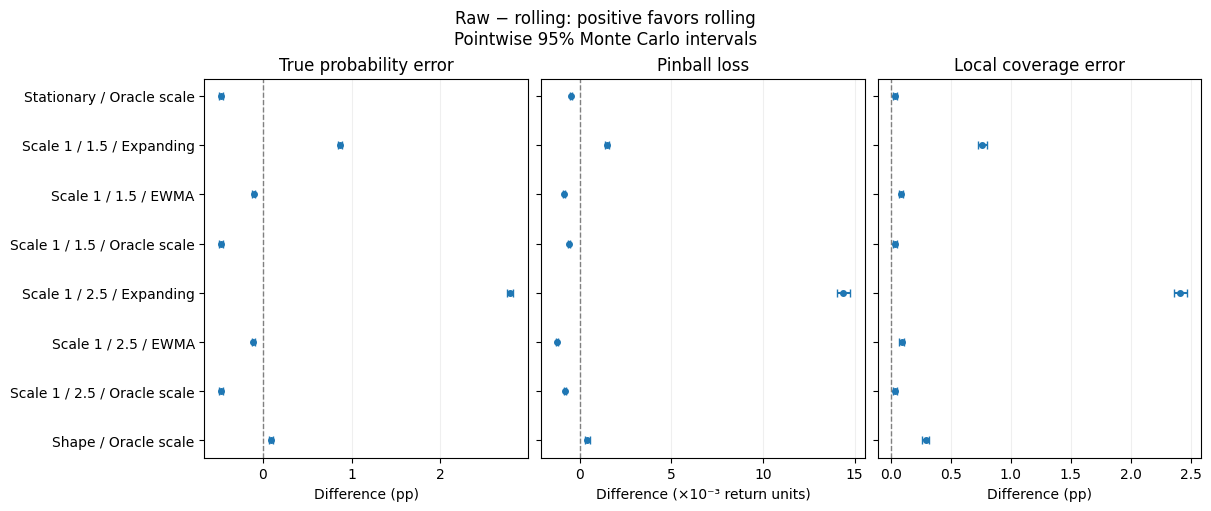

In [9]:
plot_comparison(
    "raw_minus_rolling", "Raw − rolling: positive favors rolling", "tab:blue",
)

The shape case gives a modest but measurable calibration gain: raw minus rolling is **0.099 pp** for probability error (95% interval **0.077–0.121 pp**) and **0.000409** for pinball loss (**0.000271–0.000547**). The saved raw-minus-ACI comparison also favors calibration: its loss improvement is **0.000188** (**0.000037–0.000340**). The distinction is between calibration helping and feedback adding value beyond it.

### What adaptive feedback adds

Positive rolling-minus-ACI differences favor ACI.

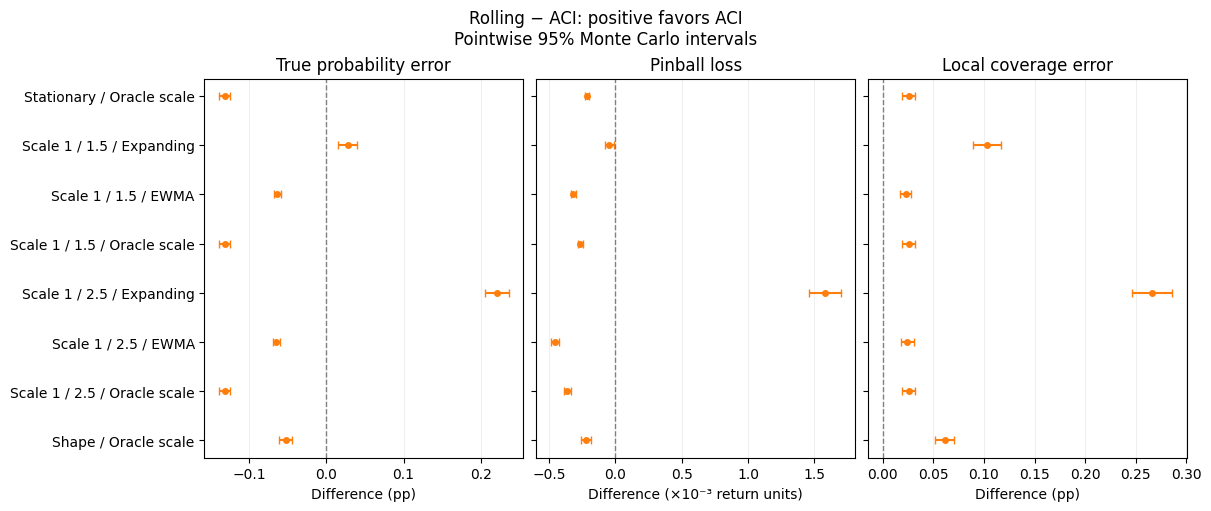

In [10]:
plot_comparison(
    "rolling_minus_aci", "Rolling − ACI: positive favors ACI", "tab:orange",
)

For the severe scale change with expanding volatility, ACI adds **0.221 pp** of probability-error improvement over rolling (**0.205–0.236 pp**) and **0.001580** of loss improvement (**0.001463–0.001696**). It lowers local coverage error relative to rolling in all eight combinations, but this is the only combination where both risk metrics also improve.

## What can we conclude?

Rolling improves the raw Gaussian forecast with slowly tracked scale changes under expanding volatility, and with changing tail shape at constant variance. With EWMA or known scale in the Student-t scenarios, raw is more accurate. These comparisons are consistent with a trade-off between correcting the tail assumption and introducing estimation variability. Evaluating calibration therefore requires comparison with the original forecast.

ACI answers the next question. At the chosen settings, its clearest additional accuracy gain occurs with large scale changes and expanding volatility. Elsewhere its benefit is mainly better recent breach counts, sometimes at a cost in probability error and loss. Calibration and adaptation should be judged separately, using accuracy and coverage together.

These are whole-period results for specific synthetic distributions at the 5% level. Intervals measure simulation uncertainty and are pointwise, without a multiple-comparison adjustment. The Gaussian benchmark was specified after inspecting the rolling/ACI results on these trajectories, so its comparison is exploratory. The study establishes neither performance on market data nor exchangeability-based guarantees for changing regimes.

The next step is the planned window/learning-rate sensitivity analysis and evaluation after regime changes. A shorter rolling window remains essential before attributing the observed benefit specifically to ACI feedback.